# Project A | Day 02. 배송 지연 분포와 고객 평가의 연관성 검증

**프로젝트 목표:** 배송 지연과 고객 평가의 관계를 통계적으로 확인한 뒤, SQL·Tableau로 지역·판매자·상품군별 운영 개선 우선순위를 진단한다.

**분석 단위와 정의**
- 배송 품질 분석: `order_status='delivered'`이고 실제/예상 배송일이 모두 존재하는 **주문 96,470건**. 한 행은 주문 1건이다.
- `delay_days`: `실제 고객 배송일::date − 예상 배송일::date` (음수=조기, 0=예정일 당일, 양수=지연).
- 지연 분포 그룹: 정시·조기(`≤0`), Delay A(1–7일), Delay B(8–22일), Delay C(23일 이상). 7일·22일은 지연 주문의 중앙값·90백분위수를 참고한 **탐색적 구간**이다.
- 고객 만족도 분석: 주문에 리뷰가 **정확히 1건** 있는 95,299건. 저평점은 리뷰 점수 1~2점이다.
- 리뷰 미관측 646건과 복수 리뷰 525건은 만족도 분석에서 제외하되, 배송 품질 전체 분모에서는 제외하지 않는다.

**재현 방법:** [데이터 준비](../README.md#데이터-준비)에서 원본 CSV 9개를 내려받아 PostgreSQL에 적재한다. 저장소 루트에서 requirements.txt의 패키지를 설치하고 .env에 로컬 접속 정보를 설정한다. 그 Python 환경을 커널로 선택해 Restart Kernel → Run All을 실행하고 마지막 셀의 PASS를 확인한다. .env와 접속 암호는 로컬에 보관한다.

**Day 02의 완료 범위:** 분포 EDA, 리뷰 관측 상태 검증, 저평점 관련 통계 검정 및 단순 회귀모형의 적합 패턴 검토. 이후 비선형 모형 확장은 보류하고 Day 03 SQL 분석 View 구축으로 진행한다.


In [1]:
import sys

print(sys.version)
print(sys.executable)

3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]
c:\Users\glim1\anaconda3\envs\olist\python.exe


In [2]:
import pandas as pd
import sqlalchemy
import psycopg
import matplotlib
import seaborn as sns
from dotenv import load_dotenv

print("pandas:", pd.__version__)
print("SQLAlchemy:", sqlalchemy.__version__)
print("psycopg:", psycopg.__version__)
print("라이브러리 불러오기 성공")

pandas: 3.1.1
SQLAlchemy: 2.1.8
psycopg: 3.3.8
라이브러리 불러오기 성공


In [3]:
import os
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# 1. 환경변수 로드
load_dotenv(find_dotenv(usecwd=True))

# 2. 데이터베이스 접속 정보 구성
db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT", "5432")),
    database=os.getenv("DB_NAME")
)

# 3. SQLAlchemy 엔진 생성
engine = create_engine(db_url)

# 4. 연결 후 SQL 실행
with engine.connect() as conn:
    result = conn.execute(
        text("SELECT COUNT(*) FROM public.orders")
    )
    order_count = result.scalar_one()

print("PostgreSQL 연결 성공")
print("orders 전체 행 수:", order_count)

PostgreSQL 연결 성공
orders 전체 행 수: 99441


## A-07. 배송 지연 분포 EDA

먼저 배송 완료 주문을 **주문 단위로 추출**하여 지연 규모와 분포를 확인한다. 배송 지연율의 분모는 리뷰 보유 여부와 관계없이 96,470건이다.


In [4]:
query = """
SELECT  order_id,
        order_delivered_customer_date::date - order_estimated_delivery_date::date AS delay_days
  FROM  public.orders
 WHERE  order_status = 'delivered'
   AND  order_delivered_customer_date IS NOT NULL
   AND  order_estimated_delivery_date IS NOT NULL
"""

with engine.connect() as conn:
    df = pd.read_sql(text(query), conn)

print(df.shape)
display(df.head())


(96470, 2)


,order_id,delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,-8
1,53cdb2fc8bc7dce0b6741e2150273451,-6
2,47770eb9100c2d0c44946d9cf07ec65d,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,-10


In [5]:
print("DataFrame 행 수 :", df.shape[0])
print("고유 주문 ID 수 :", df['order_id'].nunique())
print("delay_days > 0 인 주문 수 :", (df['delay_days'] > 0).sum())

DataFrame 행 수 : 96470
고유 주문 ID 수 : 96470
delay_days > 0 인 주문 수 : 6534


In [6]:
#TASK A-07-6. 배송 지연 일수의 기술통계 분석

df_delayed = df[df['delay_days'] > 0].copy()

df_delayed.describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
)


,delay_days
count,6534.000000
mean,10.620141
std,14.644955
min,1.000000
25%,3.000000
50%,7.000000
75%,13.000000
90%,22.000000
95%,31.000000
max,188.000000


<Axes: xlabel='delay_days', ylabel='Count'>

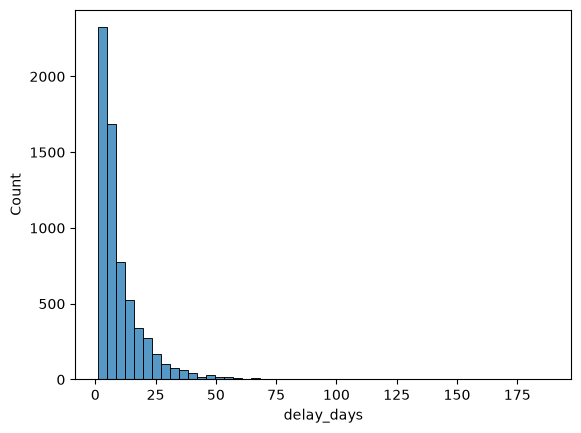

In [7]:
#TASK A-07-7. Histogram과 Boxplot 작성
sns.histplot(data=df_delayed, x="delay_days", bins=50)

<Axes: xlabel='delay_days'>

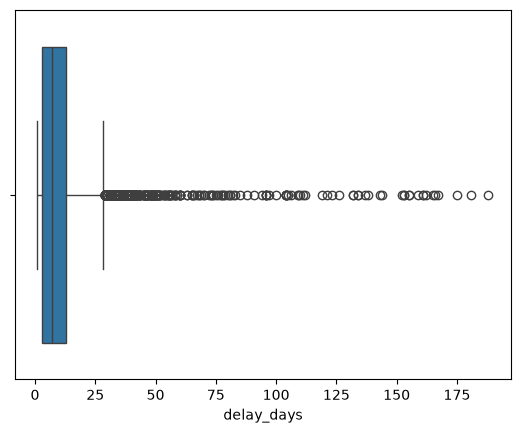

In [8]:
sns.boxplot(data=df_delayed, x="delay_days")

In [9]:
#TASK A-07-8. 배송 지연 구간별 주문 수 계산
df["delay_group"] = pd.cut(
    df["delay_days"],
    bins=[-float("inf"), 0, 7, 22, float("inf")],
    labels=["On Time/Early", "Delay_A", "Delay_B", "Delay_C"]
)

df["delay_group"].value_counts(
    normalize=True
).sort_index() * 100

delay_group
On Time/Early    93.226910
Delay_A           3.806365
Delay_B           2.295014
Delay_C           0.671711
Name: proportion, dtype: float64

## A-08. 리뷰 데이터 품질과 분석 대상 선정

Olist 리뷰는 주문당 여러 행이 존재할 수 있다. 리뷰 개수·미관측 여부를 먼저 점검하고, **주문별 중복이 생기지 않도록 집계 후 결합**한다.


In [10]:
#TASK A-08-1. 복수 리뷰의 원인 탐색
query = """
SELECT  order_id,
        COUNT(review_id) AS review_count,
        COUNT(DISTINCT review_id) AS distinct_review_id,
        COUNT(DISTINCT review_score) AS distinct_score,
        MIN(review_answer_timestamp) AS first_review_answer,
        MAX(review_answer_timestamp) AS last_review_answer
  FROM  public.reviews
 GROUP
    BY  order_id
--단일집계 조건(필요시 HAVING절 사용)    
--HAVING  COUNT(review_id) > 1 
"""

with engine.connect() as conn:
    review_df = pd.read_sql(text(query), conn)

In [11]:
review_df.head(10)
# review_df[review_df['distinct_score'] > 1].shape

,order_id,review_count,distinct_review_id,distinct_score,first_review_answer,last_review_answer
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,2017-09-22 10:57:03,2017-09-22 10:57:03
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,2017-05-15 11:34:13,2017-05-15 11:34:13
2,000229ec398224ef6ca0657da4fc703e,1,1,1,2018-01-23 16:06:31,2018-01-23 16:06:31
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,2018-08-15 16:39:01,2018-08-15 16:39:01
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,2017-03-03 10:54:59,2017-03-03 10:54:59
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,1,1,2017-05-24 19:00:09,2017-05-24 19:00:09
6,00054e8431b9d7675808bcb819fb4a32,1,1,1,2017-12-29 02:40:12,2017-12-29 02:40:12
7,000576fe39319847cbb9d288c5617fa6,1,1,1,2018-07-11 20:14:25,2018-07-11 20:14:25
8,0005a1a1728c9d785b8e2b08b904576c,1,1,1,2018-04-02 00:52:01,2018-04-02 00:52:01
9,0005f50442cb953dcd1d21e1fb923495,1,1,1,2018-07-05 23:17:04,2018-07-05 23:17:04


In [12]:
print("전체 주문 수:", len(review_df))
print("주문 ID 중복:", review_df["order_id"].duplicated().sum())
print("전체 리뷰 행 수:", review_df["review_count"].sum())

display(review_df["review_count"].value_counts().sort_index())

전체 주문 수: 98673
주문 ID 중복: 0
전체 리뷰 행 수: 99224


review_count
1    98126
2      543
3        4
Name: count, dtype: int64

In [13]:
df_merged= df.merge(
    review_df, 
    how='left',
    on='order_id',
    validate='one_to_one'
)

df_merged["review_status"] = df_merged["review_count"].apply(
    lambda x: "No Review" if pd.isna(x) 
    else "Single Review" if x == 1
    else "Multiple Reviews"
)
df_merged["review_status"].value_counts().sort_index()

review_status
Multiple Reviews      525
No Review             646
Single Review       95299
Name: count, dtype: int64

In [14]:
#TASK A-08-3. 리뷰 유형별 배송 지연율 비교
df_merged["is_delayed"] = df_merged["delay_days"] > 0
review_delay_df = df_merged.groupby("review_status").agg(
    total_orders=("order_id", "count"),
    delayed_orders=("is_delayed", "sum"),
    delay_rate=("is_delayed", "mean")
)
review_delay_df = review_delay_df.reindex(
    ["No Review", "Single Review", "Multiple Reviews"]
    )

review_delay_df["delay_rate_pct"] = (
    review_delay_df["delay_rate"] * 100
).round(2)

display(review_delay_df)

,total_orders,delayed_orders,delay_rate,delay_rate_pct
review_status,,,,
No Review,646,153,0.236842,23.68
Single Review,95299,6353,0.066664,6.67
Multiple Reviews,525,28,0.053333,5.33


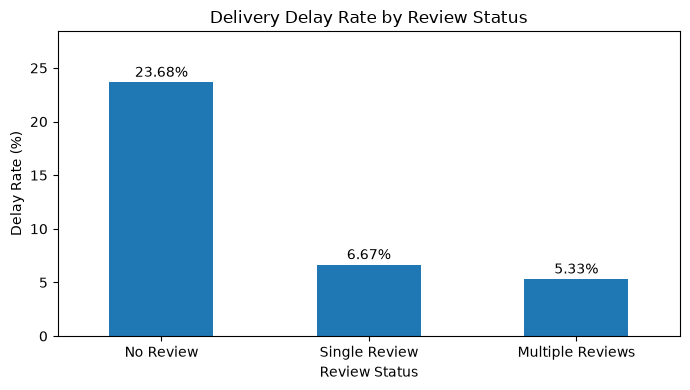

In [15]:
import matplotlib.pyplot as plt

ax = review_delay_df["delay_rate_pct"].plot(
    kind="bar",
    figsize=(7, 4),
    title="Delivery Delay Rate by Review Status",
    ylabel="Delay Rate (%)",
    xlabel="Review Status",
    rot=0,
    legend=False
)

for i, rate in enumerate(review_delay_df["delay_rate_pct"]):
    ax.text(i, rate + 0.5, f"{rate:.2f}%",
            ha="center")

ax.set_ylim(0, review_delay_df["delay_rate_pct"].max() * 1.2)

plt.tight_layout()
plt.show()

review_status,Multiple Reviews,No Review,Single Review
delay_group,,,
On Time/Early,497,493,88946
Delay_A,12,72,3588
Delay_B,11,57,2146
Delay_C,5,24,619


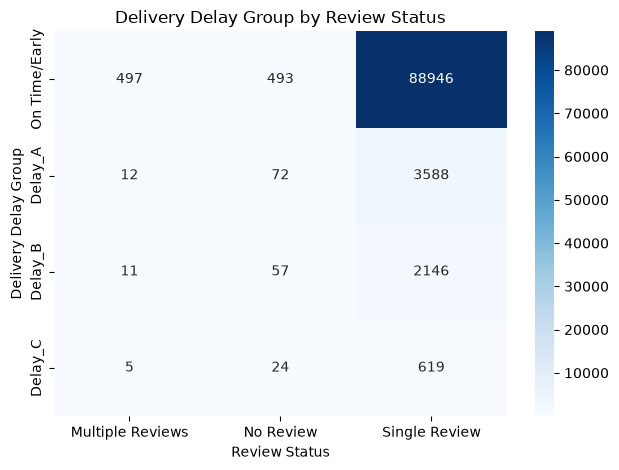

In [16]:
# TASK A-08-4. 배송 지연 수준 × 리뷰 유형 교차표

cross_tab = pd.crosstab(
    df_merged["delay_group"],
    df_merged["review_status"]
)

display(cross_tab)

sns.heatmap(
    cross_tab,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Delivery Delay Group by Review Status")
plt.xlabel("Review Status")
plt.ylabel("Delivery Delay Group")
plt.tight_layout()
plt.show()


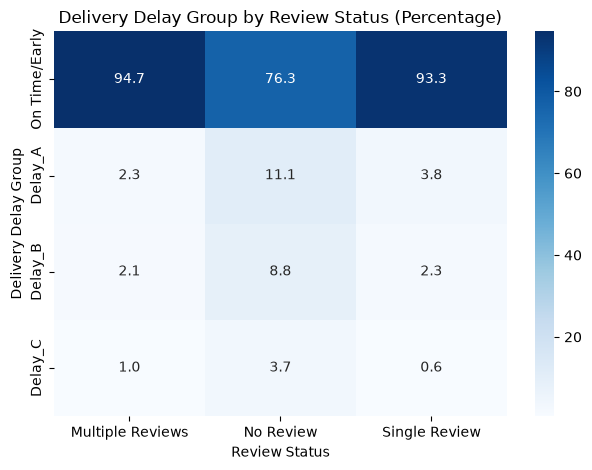

In [17]:
cross_pct = pd.crosstab(
    df_merged["delay_group"],
    df_merged["review_status"],
    normalize="columns"
) * 100

sns.heatmap(
    cross_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)
plt.title("Delivery Delay Group by Review Status (Percentage)")
plt.xlabel("Review Status")
plt.ylabel("Delivery Delay Group")
plt.tight_layout()
plt.show()

In [18]:
#TASK A-08-5. 리뷰 유형과 배송 지연의 연관성 검증
import scipy.stats as stats

chi2, p_value, dof, expected = stats.chi2_contingency(cross_tab)
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4e}")
print(f"Minimum expected frequency: {expected.min():.2f}")

Chi-square statistic: 326.3120
Degrees of freedom: 6
P-value: 1.8696e-67
Minimum expected frequency: 3.53


### TASK A-08-5. 카이제곱 독립성 검정 결과

- **목적:** 리뷰 유형과 배송 지연 수준의 연관성 검증
- **방법:** Pearson 카이제곱 독립성 검정 (4×3 교차표)
- **결과:** χ²(6) = 326.31, p < 0.001
- **해석:** 귀무가설을 기각하므로 리뷰 유형과 배송 지연 수준 사이에 통계적으로 유의한 연관성이 확인됨.
- **주의:** 최소 기대빈도가 3.53으로 일부 셀이 5 미만이므로 추가 검정 필요. 관측된 연관성만으로 인과관계를 설명할 수 없음.

review_status,Multiple Reviews,No Review,Single Review
is_delayed,,,
False,497,493,88946
True,28,153,6353


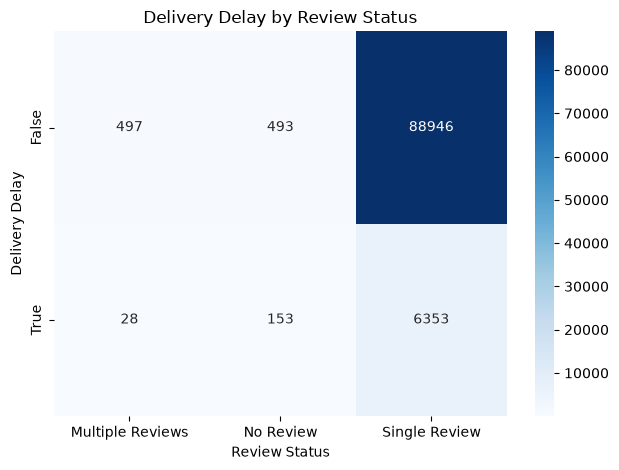

In [19]:
#TASK A-08-6. 배송지연 여부에 따라 재검증
cross_tab_binary = pd.crosstab(
    df_merged["is_delayed"],
    df_merged["review_status"]
)
display(cross_tab_binary)

sns.heatmap(
    cross_tab_binary,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Delivery Delay by Review Status")
plt.xlabel("Review Status")
plt.ylabel("Delivery Delay")
plt.tight_layout()
plt.show()


In [20]:
chi2, p_value, dof, expected = stats.chi2_contingency(cross_tab_binary)
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4e}")
print(f"Minimum expected frequency: {expected.min():.2f}")

Chi-square statistic: 296.0249
Degrees of freedom: 2
P-value: 5.2361e-65
Minimum expected frequency: 35.56


### TASK A-08-5(보완). 리뷰 유형과 배송 지연 여부의 독립성 검정

- 방법: Pearson 카이제곱 독립성 검정 (2×3 교차표)
- 결과: χ²(2) = 296.02, p < 0.001
- 검정 조건: 최소 기대빈도 35.56으로 적절
- 해석: 리뷰 유형과 배송 지연 여부 사이에 통계적으로 유의한 연관성이 확인됨.
- 주요 발견: 리뷰 미관측 주문의 지연율(23.68%)이 단일 리뷰(6.67%) 및 복수 리뷰(5.33%) 주문보다 높음.
- 한계: 전체 검정만으로 집단 간 개별 차이나 인과관계를 확인할 수 없음.


In [21]:
#TASK A-08-6. 집단별 배송 지연율 비교
from statsmodels.stats.proportion import proportions_ztest

groups = ["No Review", "Single Review"]

count = review_delay_df.loc[groups, "delayed_orders"]
nobs = review_delay_df.loc[groups, "total_orders"]
print(count, nobs)

z_stat, p_value = proportions_ztest(
    count=count,
    nobs=nobs,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4e}")

review_status
No Review         153
Single Review    6353
Name: delayed_orders, dtype: int64 review_status
No Review          646
Single Review    95299
Name: total_orders, dtype: int64
Z-statistic: 17.1457
P-value: 6.7683e-66


### TASK A-08-6. No Review vs Single Review 비율 검정

- **방법:** 두 표본 비율 Z-검정 (양측검정)
- **결과:** Z = 17.1457, p < 0.001
- **비율:** No Review 23.68%, Single Review 6.67%
- **해석:** 두 집단의 배송 지연율은 통계적으로 유의하게 다르며, 리뷰 미관측 집단의 지연율이 약 17.02%p 높게 나타났다.
- **한계:** 리뷰 미작성의 원인을 확인할 수 없으며, 리뷰가 있는 주문만 분석할 경우 표본 선택 편향이 발생할 가능성이 있다.

In [22]:
groups = ["Multiple Reviews", "Single Review"]

count = review_delay_df.loc[groups, "delayed_orders"]
nobs = review_delay_df.loc[groups, "total_orders"]
print(count, nobs)

z_stat, p_value = proportions_ztest(
    count=count,
    nobs=nobs,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4e}")

review_status
Multiple Reviews      28
Single Review       6353
Name: delayed_orders, dtype: int64 review_status
Multiple Reviews      525
Single Review       95299
Name: total_orders, dtype: int64
Z-statistic: -1.2218
P-value: 2.2179e-01


### TASK A-08-6. 복수 리뷰와 단일 리뷰 비교

- 방법: 두 표본 비율 Z-검정 (양측)
- 결과: Z = -1.2218, p = 0.2218
- 배송 지연율: 복수 리뷰 5.33%, 단일 리뷰 6.67%
- 비율 차이: -1.33%p
- 95% 신뢰구간(Newcombe): [-2.96, 0.94]%p
- 해석: 두 집단 사이에서 통계적으로 유의한 배송 지연율 차이를 발견하지 못함.
- 한계: 두 집단이 동등하다는 의미는 아니며, 복수 리뷰의 평가값을 대표하는 기준은 여전히 불명확함.

### TASK A-08. 리뷰 데이터 검증 및 분석 대상 선정 결론

**1. 복수 리뷰 주문 (Multiple Reviews)**

단일 리뷰 주문과 복수 리뷰 주문의 배송 지연율을 비교한 결과, 통계적으로 유의한 차이를 발견하지 못했다(Z = -1.2218, p = 0.2218).

그러나 동일 주문에 여러 리뷰가 존재하는 원인을 확인할 수 없으며, 최초·최신 리뷰 또는 평균 점수 중 어떤 값을 대표값으로 사용할지 합리적인 기준을 설정하기 어렵다. 따라서 **복수 리뷰 주문은 주 분석에서 제외**하기로 결정하였다.

**2. 리뷰 미관측 주문 (No Review)**

리뷰가 없는 주문의 배송 지연율은 23.68%로, 단일 리뷰 주문의 6.67%보다 유의하게 높게 나타났다(Z = 17.1457, p < 0.001).

이는 리뷰 미관측 여부와 배송 지연 사이에 연관성이 있음을 시사하지만, 리뷰가 작성되지 않은 원인은 확인할 수 없다. 따라서 리뷰 점수가 없는 주문은 고객 만족도 분석에서 제외하되, **이로 인한 표본 선택 편향 가능성을 분석의 한계로 명시**한다.

후속 SQL 운영 분석에서는 판매자별 리뷰 미관측 비율을 보조 품질 지표로 점검할 수 있다. 다만 리뷰 미관측을 고객 불만족으로 직접 해석해서는 안 된다.

**3. 최종 분석 대상**

배송 지연과 고객 평가 점수의 관계를 분석하기 위해 **리뷰가 정확히 1건 존재하는 주문 95,299건을 주 분석 대상으로 선정**하였다. 리뷰 점수의 유효성을 최종 검증한 후 분석을 진행한다.

이번 대상 선정은 고객 평가의 측정 기준을 일관되게 유지하기 위한 결정이며, 분석 결과를 전체 주문으로 일반화할 때에는 리뷰 미관측에 따른 선택 편향 가능성을 고려한다.


## A-09. 배송 지연과 저평점의 연관성 검정

리뷰가 정확히 1건인 주문을 대상으로 저평점(1~2점) 비율, 집단 간 차이, 신뢰구간을 분석한다. 다른 판매자·상품·지역 요인을 통제하지 않은 **관측적 연관성**임에 유의한다.


In [23]:
# TASK A-09-1. 분석용 데이터셋 구축
single_df = df_merged[df_merged["review_status"] == "Single Review"]

query = """
    SELECT  order_id, review_score
      FROM  public.reviews
"""
with engine.connect() as conn:
    review_raw = pd.read_sql(text(query), conn)

review_single = review_raw[
    review_raw["order_id"].isin(single_df["order_id"])
].copy()

analysis_df = single_df[["order_id", "delay_days", "delay_group"]].merge(
    review_single, 
    how = 'left',
    on = 'order_id',
    validate = 'one_to_one'
    )

print("전체 주문 수:", len(analysis_df))
print("고유 주문 수:", analysis_df["order_id"].nunique())
print("리뷰 점수 결측:", analysis_df["review_score"].isna().sum())
print("리뷰 점수 범위:",
      analysis_df["review_score"].min(),
      analysis_df["review_score"].max())

display(analysis_df.head())


전체 주문 수: 95299
고유 주문 수: 95299
리뷰 점수 결측: 0
리뷰 점수 범위: 1 5


,order_id,delay_days,delay_group,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,-8,On Time/Early,4
1,53cdb2fc8bc7dce0b6741e2150273451,-6,On Time/Early,4
2,47770eb9100c2d0c44946d9cf07ec65d,-18,On Time/Early,5
3,949d5b44dbf5de918fe9c16f97b45f8a,-13,On Time/Early,5
4,ad21c59c0840e6cb83a9ceb5573f8159,-10,On Time/Early,5


<Axes: xlabel='review_score'>

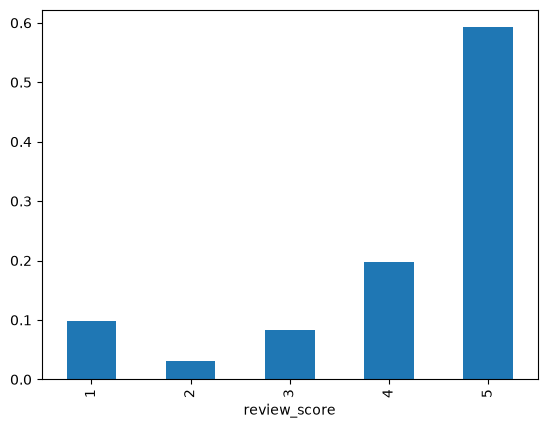

In [24]:
analysis_df["review_score"].value_counts(normalize=True).sort_index().plot(kind= "bar")

### TASK A-09-2. 리뷰 점수 분포 분석

단일 리뷰 주문 95,299건의 평가 점수를 분석한 결과, 4~5점이 전체의 78.96%를 차지했으며, 특히 5점에 평가가 집중되었다.

반면 1~2점의 저평점 비율은 12.79%였다. 리뷰 점수가 높은 구간에 집중되어 있으므로 향후 분석에서는 평균 점수와 함께 저평점 비율을 주요 지표로 활용한다.

단, 이 분포는 리뷰가 정확히 1건 존재하는 주문에 한정된 결과이다.

review_score,1,2,3,4,5
delay_group,,,,,
On Time/Early,6.602883,2.646550,8.062195,20.407888,62.280485
Delay_A,41.304348,7.998885,12.318841,14.409142,23.968785
Delay_B,69.944082,10.531221,8.853681,4.147251,6.523765
Delay_C,69.789984,5.492730,9.208401,6.785137,8.723748


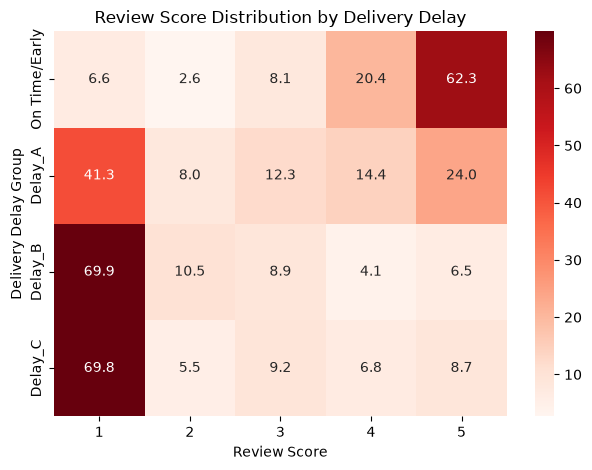

In [25]:
# TASK A-09-3. 배송 지연 수준별 리뷰 점수 분포
score_by_group = pd.crosstab(
    analysis_df["delay_group"],
    analysis_df["review_score"],
    normalize ="index" 
) *100
display(score_by_group)

sns.heatmap(
    score_by_group, 
    annot=True,
    fmt=".1f",
    cmap="Reds"
)

plt.title("Review Score Distribution by Delivery Delay")
plt.xlabel("Review Score")
plt.ylabel("Delivery Delay Group")
plt.tight_layout()
plt.show()


배송 지연 수준별 리뷰 점수 분포를 분석한 결과, 정시·조기 배송 주문의 저평점 비율은 약 9.2%인 반면, 지연 배송 그룹에서는 약 49.3~80.4%로 높게 나타났다. 이는 배송 지연과 낮은 고객 평가 사이의 강한 연관성을 시사한다. 다만 지연 기간에 따른 저평점 비율이 완전히 단조 증가하지 않으며, 관측된 차이를 배송 지연의 인과적 효과로 해석할 수는 없다.

In [26]:
# TASK A-09-4. 배송 지연 그룹별 저평점 비율 분석
analysis_df["is_low_rating"] = analysis_df["review_score"] <= 2 

low_rating_df = analysis_df.groupby(
    "delay_group", observed=True
).agg(
    order_count=("order_id", "size"),
    low_rating_orders=("is_low_rating", "sum"),
    low_rating_rate=("is_low_rating", "mean")
)

low_rating_df["low_rating_pct"] = (
    low_rating_df["low_rating_rate"] * 100
).round(2)

display(low_rating_df)

,order_count,low_rating_orders,low_rating_rate,low_rating_pct
delay_group,,,,
On Time/Early,88946,8227,0.092494,9.25
Delay_A,3588,1769,0.493032,49.30
Delay_B,2146,1727,0.804753,80.48
Delay_C,619,466,0.752827,75.28


### TASK A-09-4. 배송 지연 수준별 저평점 비율

단일 리뷰 주문 95,299건을 대상으로 배송 지연 수준별 저평점(1~2점) 비율을 분석하였다.

정시·조기 배송 주문의 저평점 비율은 9.25%였으나, 1~7일 지연 주문은 49.30%, 8~22일 지연 주문은 80.48%, 23일 이상 지연 주문은 75.28%로 나타났다.

배송 지연 그룹에서 저평점 비율이 현저히 높게 관측되었으나, 지연 기간에 따라 비율이 일관되게 증가하지는 않았다.

이러한 차이의 통계적 유의성과 효과크기는 아래 카이제곱 검정 및 Cramér's V로 확인한다. 관측된 연관성을 배송 지연의 인과적 효과로 해석할 수는 없다.


In [27]:
# TASK A-09-5 통계적 검증
import numpy as np

islow_delay = pd.crosstab(
    analysis_df["delay_group"],
    analysis_df["is_low_rating"]
)

chi2, p_value, dof, expected = stats.chi2_contingency(islow_delay)
n = islow_delay.to_numpy().sum()
r, c = islow_delay.shape

cramers_v =  np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4e}")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"Minimum expected frequency: {expected.min():.2f}")

Chi-square statistic: 16269.3759
Degrees of freedom: 3
P-value: 0.0000e+00
Cramér's V: 0.4132
Minimum expected frequency: 79.17


In [28]:
# TASK A-09-6. 저평점 비율의 신뢰구간 분석
from statsmodels.stats.proportion import proportion_confint
groups = low_rating_df.index.tolist()

for delay_group in groups:
    ci_low, ci_high = proportion_confint(
        low_rating_df.loc[delay_group, "low_rating_orders"],
        low_rating_df.loc[delay_group, "order_count"],
        alpha = 0.05,
        method = "wilson"
    )
    
    print(
        f"{delay_group}: "
        f"95% CI = [{ci_low*100:.2f}%, {ci_high*100:.2f}%]"
    )

On Time/Early: 95% CI = [9.06%, 9.44%]
Delay_A: 95% CI = [47.67%, 50.94%]
Delay_B: 95% CI = [78.74%, 82.10%]
Delay_C: 95% CI = [71.74%, 78.52%]


배송 지연 수준별 저평점 비율의 95% Wilson 신뢰구간을 산출하였다. 정시·조기 배송 그룹은 표본 수가 많아 추정의 불확실성이 작았으며, Delay C는 상대적으로 넓은 신뢰구간을 보였다. 특히 Delay B의 저평점 비율이 Delay C보다 약 5.19%p 높게 관측되어, 두 집단의 비율 차이는 다음 셀에서 탐색적으로 검정한다.


In [29]:
#TASK A-09-7. Delay B와 Delay C의 저평점 비율 차이를 직접 검정
from statsmodels.stats.proportion import confint_proportions_2indep

z_stat, p_value = proportions_ztest(
    count=[low_rating_df.loc["Delay_B", "low_rating_orders"], 
           low_rating_df.loc["Delay_C", "low_rating_orders"]],
    nobs=[low_rating_df.loc["Delay_B", "order_count"], 
           low_rating_df.loc["Delay_C", "order_count"]],
    alternative="two-sided"
)

ci_low, ci_high = confint_proportions_2indep(
    count1=low_rating_df.loc["Delay_B", "low_rating_orders"],
    nobs1=low_rating_df.loc["Delay_B", "order_count"],
    count2=low_rating_df.loc["Delay_C", "low_rating_orders"],
    nobs2=low_rating_df.loc["Delay_C", "order_count"],
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print(f"Z = {z_stat:.4f}")
print(f"p-value = {p_value:.4e}")
print(f"95% CI = [{ci_low*100:.2f}, {ci_high*100:.2f}] %p")

Z = 2.8098
p-value = 4.9573e-03
95% CI = [1.52, 9.09] %p


### TASK A-09-7. Delay B와 Delay C의 저평점 비율 비교

Delay B(8~22일)의 저평점 비율은 80.48%, Delay C(23일 이상)는 75.28%로, 약 5.19%p 차이가 관측되었다.

두 표본 비율 Z-검정 결과 통계적으로 유의한 차이가 확인되었으며(Z ≈ 2.81, p ≈ 0.005), 비율 차이의 95% Newcombe 신뢰구간은 약 [1.52, 9.09]%p로 추정되었다.

이는 두 집단의 저평점 비율에 차이가 있음을 시사하지만, 차이의 정확한 크기에는 불확실성이 존재한다. 또한 해당 비교는 탐색적 사후 분석이므로 다중비교 가능성을 고려해야 하며, 배송 지연이 저평점의 직접적인 원인이라고 단정할 수 없다.

## A-10. 탐색적 로지스틱 회귀분석

지연 여부 모형과 날짜 차이 연속형 모형을 비교한다. 오즈비는 **확률비**가 아니며, 단순 연속형 모형의 계수는 로그 오즈가 날짜 차이에 선형적으로 변한다고 가정한다.


In [30]:
# TASK A-10. 로지스틱 회귀분석
import statsmodels.formula.api as smf

analysis_df["is_delayed"] = (analysis_df["delay_days"] > 0).astype(int)
analysis_df["is_low_rating"] = analysis_df["is_low_rating"].astype(int)

model = smf.logit(
    formula="is_low_rating ~ is_delayed",
    data=analysis_df
).fit(disp=False)

model.summary()



<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:          is_low_rating   No. Observations:                95299
Model:                          Logit   Df Residuals:                    95297
Method:                           MLE   Df Model:                            1
Date:                Fri, 13 Nov 2026   Pseudo R-squ.:                  0.1321
Time:                        21:08:33   Log-Likelihood:                -31627.
converged:                       True   LL-Null:                       -36440.
Covariance Type:            nonrobust   LLR p-value:                     0.000
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.2836      0.012   -197.313      0.000      -2.306      -2.261
is_delayed     2.7886      0.028     98.311      0.000       2.733       2.844
==============================================================================
"""

In [31]:
# 회귀계수 → 오즈비
or_binary = np.exp(model.params)

# 회귀계수 신뢰구간 → 오즈비 신뢰구간
or_binary_ci = np.exp(model.conf_int())

print("Odds Ratios:")
display(or_binary)

print("95% CI:")
display(or_binary_ci)


Odds Ratios:


Intercept      0.101921
is_delayed    16.258077
dtype: float64

95% CI:


,0,1
Intercept,0.099636,0.104260
is_delayed,15.378885,17.187531


### TASK A-10. 배송 지연과 저평점 발생의 로지스틱 회귀분석

단일 리뷰 주문 95,299건을 대상으로 배송 지연 여부를 독립변수, 저평점 여부(1~2점)를 종속변수로 설정하여 로지스틱 회귀분석을 수행하였다.

배송 지연 여부의 회귀계수는 2.7886으로 통계적으로 유의했으며(p < 0.001), 오즈비는 약 16.26으로 추정되었다.

이는 배송 지연 주문의 저평점 발생 오즈가 정시·조기 배송 주문보다 약 16.26배 높다는 의미이다.

다만 다른 요인을 통제하지 않은 단변량 모형이며, 리뷰가 정확히 1건 존재하는 주문에 한정된 결과이므로 배송 지연의 인과적 효과로 해석할 수 없다.

In [32]:
# TASK A-10-2. 연속형 로지스틱 회귀분석

model_days = smf.logit(
    formula="is_low_rating ~ delay_days",
    data=analysis_df
).fit(disp=False)

display(model_days.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:          is_low_rating   No. Observations:                95299
Model:                          Logit   Df Residuals:                    95297
Method:                           MLE   Df Model:                            1
Date:                Fri, 13 Nov 2026   Pseudo R-squ.:                 0.08062
Time:                        21:08:33   Log-Likelihood:                -33503.
converged:                       True   LL-Null:                       -36440.
Covariance Type:            nonrobust   LLR p-value:                     0.000
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.1899      0.013    -89.519      0.000      -1.216      -1.164
delay_days     0.0754      0.001     70.362      0.000       0.073       0.078
==============================================================================
"""

In [33]:
# 회귀계수 → 오즈비
or_days = np.exp(model_days.params)

# 회귀계수 신뢰구간 → 오즈비 신뢰구간
or_days_ci = np.exp(model_days.conf_int())

print("Odds Ratios:")
display(or_days)

print("95% CI:")
display(or_days_ci)


Odds Ratios:


Intercept     0.304249
delay_days    1.078332
dtype: float64

95% CI:


,0,1
Intercept,0.296425,0.31228
delay_days,1.076069,1.08060


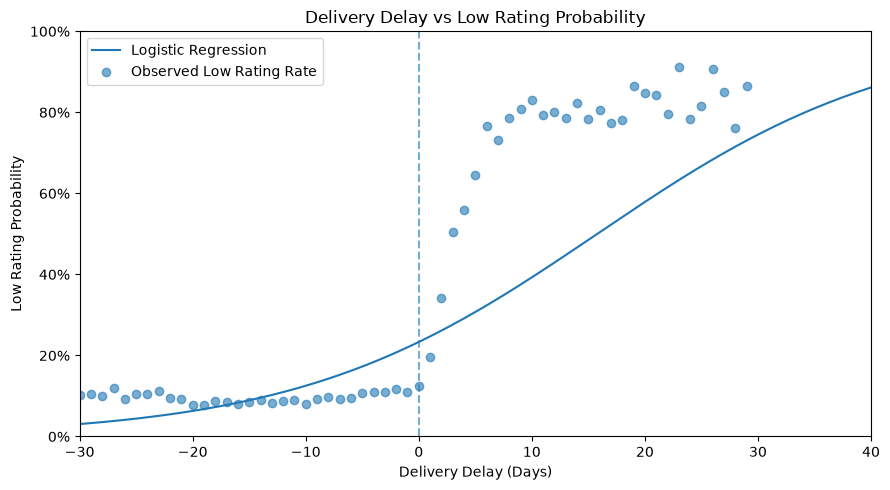

In [34]:
# TASK A-10-3. 로지스틱 회귀곡선 시각화

from matplotlib.ticker import PercentFormatter

# 1. 예측에 사용할 지연 일수
x_grid = np.linspace(-30, 40, 300)

# 2. 로지스틱 회귀모형의 예측 확률
y_pred = model_days.predict(
    pd.DataFrame({"delay_days": x_grid})
)

# 3. 실제 지연 일수별 저평점 비율
observed = analysis_df.groupby("delay_days").agg(
    low_rating_rate=("is_low_rating", "mean"),
    n=("is_low_rating", "size")
)

# 관측치가 30건 이상인 날짜만 시각화
observed = observed[
    (observed["n"] >= 30) &
    (observed.index >= -30) &
    (observed.index <= 40)
]

# 4. 그래프
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    x_grid, y_pred,
    label="Logistic Regression"
)

ax.scatter(
    observed.index,
    observed["low_rating_rate"],
    alpha=0.6,
    label="Observed Low Rating Rate"
)

ax.axvline(0, linestyle="--", alpha=0.6)

ax.set(
    title="Delivery Delay vs Low Rating Probability",
    xlabel="Delivery Delay (Days)",
    ylabel="Low Rating Probability",
    xlim=(-30, 40),
    ylim=(0, 1)
)

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.tight_layout()
plt.show()


### TASK A-10-3. 연속형 로지스틱 회귀모형의 적합 패턴 검토

배송 예정일 대비 날짜 차이를 연속형 독립변수로 사용한 로지스틱 회귀분석 결과, 하루 증가에 따른 저평점 발생 오즈비는 1.0783으로 추정되었다(p < 0.001).

그러나 실제 관측 비율과 모형의 예측 확률을 비교한 결과, 배송 예정일을 초과한 직후 저평점 비율이 급격히 상승하고, 장기 지연 구간에서는 상승세가 둔화되는 패턴이 나타났다.

단순 로지스틱 모형은 이러한 변화를 충분히 설명하지 못하므로, 지연 발생 여부와 지연 기간을 구분하거나 비선형 관계를 허용하는 모형의 검토가 필요하다.

이는 관측자료에 기반한 연관성 분석 결과이며 인과적 효과로 해석하지 않는다.

## Day 02 검증 체크 (재실행 시 자동 확인)

아래 코드는 핵심 분모·리뷰 정책·기존 분석 결과와 데이터가 일치하는지 검사한다. **실제 로컬 DB와 연결하여 Run All을 수행해야 통과 여부를 확인할 수 있다.** 수치가 다른 데이터 버전을 사용한다면 실패 원인을 검토하고 기준값을 갱신한다.


In [35]:
# Day 02 핵심 수치와 관측 단위 검증
assert len(df) == 96_470, "배송 분석 대상 행 수가 예상과 다릅니다."
assert df["order_id"].is_unique, "배송 원천 데이터의 주문 ID가 중복됩니다."
assert df["delay_days"].notna().all(), "지연 일수 결측이 발견됐습니다."
assert int((df["delay_days"] > 0).sum()) == 6_534, "배송 지연 건수가 예상과 다릅니다."

expected_review_status = {"No Review": 646, "Single Review": 95_299, "Multiple Reviews": 525}
assert df_merged["review_status"].value_counts().to_dict() == expected_review_status, "리뷰 유형별 분모가 일치하지 않습니다."
assert len(analysis_df) == 95_299 and analysis_df["order_id"].is_unique, "리뷰 분석 데이터의 주문 단위가 깨졌습니다."
assert analysis_df["review_score"].notna().all() and analysis_df["review_score"].between(1, 5).all(), "리뷰 점수 결측 또는 범위 오류."
assert int(analysis_df["is_low_rating"].sum()) == 12_189, "저평점 주문 수가 예상과 다릅니다."

expected_groups = {"On Time/Early": (88_946, 8_227), "Delay_A": (3_588, 1_769),
                   "Delay_B": (2_146, 1_727), "Delay_C": (619, 466)}
for group, (n_orders, n_low) in expected_groups.items():
    assert int(low_rating_df.loc[group, "order_count"]) == n_orders, f"{group} 주문 수 불일치"
    assert int(low_rating_df.loc[group, "low_rating_orders"]) == n_low, f"{group} 저평점 수 불일치"

assert np.isclose(np.exp(model.params["is_delayed"]), 16.258077, rtol=1e-5), "지연 여부 OR 불일치"
assert np.isclose(np.exp(model_days.params["delay_days"]), 1.078332, rtol=1e-5), "연속형 날짜 차이 OR 불일치"
print("PASS: Day 02 관측 단위·핵심 집계·모형 수치 검증 완료")


PASS: Day 02 관측 단위·핵심 집계·모형 수치 검증 완료


### Day 02. 배송 지연과 고객 평가의 관계 분석 — 결론

Olist의 배송 완료 주문 중 리뷰가 정확히 1건 존재하는 95,299건을 대상으로 배송 지연과 고객 평가의 관계를 분석하였다.

**1. 배송 지연과 저평점 사이의 연관성**

정시·조기 배송 주문의 저평점(1~2점) 비율은 9.25%였으나, 지연 배송 주문에서는 약 62.36%로 나타났다. 카이제곱 독립성 검정에서도 통계적으로 유의한 연관성이 확인되었다(χ²(3)=16,269.38, p<0.001, Cramér's V=0.413).

**2. 배송 지연 일수에 따른 변화**

배송 예정일 대비 날짜 차이를 연속형 변수로 사용한 로지스틱 회귀분석에서 1일 증가에 대한 오즈비는 1.0783으로 추정되었다(p<0.001).

그러나 실제 관측 비율과 예측 확률을 비교한 결과, 배송 지연이 시작되는 시점부터 저평점 비율이 급격히 상승하고 장기 지연 구간에서는 상승세가 둔화되는 양상이 **시각적으로 관찰되었다**. 단순 로지스틱 회귀모형은 이러한 비선형적 패턴을 충분히 설명하지 못했다.

**3. 분석의 한계**

리뷰가 없거나 복수 리뷰가 존재하는 주문은 분석에서 제외하였다. 특히 리뷰 미관측 주문에서 배송 지연율이 상대적으로 높게 나타나 표본 선택 편향의 가능성이 존재한다.

또한 상품 품질, 판매자, 지역 등의 요인을 통제하지 않았고 동일 고객의 반복 주문에 따른 관측치 독립성도 별도로 검증하지 않았으므로, 관측된 연관성을 배송 지연의 인과적 효과로 해석할 수 없다.

**4. 후속 분석 방향**

배송 지연과 고객 저평점 사이의 연관성을 확인하였으므로, 후속 분석에서는 상품군·판매자·지역별 배송 지연 현황을 파악하고 운영 개선의 우선순위를 도출한다.
